# 04 · Explaining the model with SHAP

A score like ROC-AUC says how good the model is. It does not say **why** the model thinks a flight is risky. SHAP answers that.

**How SHAP works, in plain words.** The model starts every flight at the same point: the risk of an average flight. Then each feature pushes that risk up or down. A 7 PM departure pushes it up; a long turnaround pushes it down. SHAP measures each push. Add all the pushes to the starting point and you get exactly the model's prediction for that flight.

**How to read the numbers here.** Pushes are shown as a multiplier on the odds of arriving late:

- **×1.0** means no effect
- **×1.5** means the feature raised the odds by half
- **×0.5** means it cut them in half

`src/explain.py` computed the pushes for the all-features model on 50,000 Delta flights and 50,000 flights from all airlines, taken from the test months (July – August 2026). Delta is the focus.

**Keep in mind:** SHAP explains what the *model* learned. It shows patterns, not proven causes. A late departure hour does not cause a delay by itself; it stands for everything that has piled up by evening.

## 1. Load the SHAP values

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "load.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import plotstyle as ps
from explain import SHAP_PREFIX, load_shap
from features import FEATURE_GROUPS, TARGET

ps.apply_style()
delta = load_shap("delta")
everyone = load_shap("all")
FEATURES = [c[len(SHAP_PREFIX):] for c in delta.columns if c.startswith(SHAP_PREFIX)]
push = lambda feature: SHAP_PREFIX + feature

starting_risk = 1 / (1 + np.exp(-delta["starting_point"].iloc[0]))
print(f"Delta flights explained: {len(delta):,}   |   all-airline flights explained: {len(everyone):,}")
print(f"Features in the model: {len(FEATURES)}")
print(f"Starting point (an average flight): {starting_risk:.0%} risk of arriving late")
print(f"Average predicted risk for a Delta flight: {delta['risk'].mean():.0%}")

Delta flights explained: 50,000   |   all-airline flights explained: 50,000
Features in the model: 17
Starting point (an average flight): 19% risk of arriving late
Average predicted risk for a Delta flight: 18%


## 2. What drives the predictions for Delta?

For each flight, take the size of every push (ignoring direction) and average over all flights. A feature with large pushes matters more. The features are grouped the same way as in notebook 02.

In [2]:
GROUP_NAMES = {
    "time": "Time of day and weekday",
    "flight": "Route and airline",
    "rotation": "Aircraft rotation",
    "aircraft": "Aircraft type and age",
    "crowding": "Airport crowding",
}

def group_shares(frame: pd.DataFrame) -> pd.Series:
    sizes = {
        GROUP_NAMES[group]: frame[[push(f) for f in columns if f in FEATURES]].sum(axis=1).abs().mean()
        for group, columns in FEATURE_GROUPS.items()
    }
    sizes = pd.Series(sizes)
    return 100 * sizes / sizes.sum()

groups = pd.DataFrame({"delta_%": group_shares(delta), "all_airlines_%": group_shares(everyone)})
groups = groups.sort_values("delta_%", ascending=False)
groups.round(1)

,delta_%,all_airlines_%
Time of day and weekday,30.9,32.900002
Route and airline,27.0,24.900000
Aircraft rotation,21.0,20.700001
Aircraft type and age,10.8,9.700000
Airport crowding,10.4,11.800000


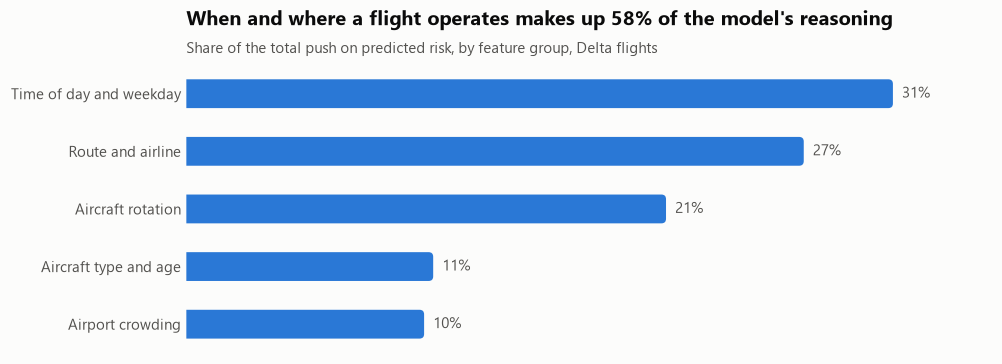

In [3]:
positions = list(range(len(groups)))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.set_xlim(0, groups["delta_%"].max() * 1.14)
ax.set_ylim(len(groups) - 0.5, -0.5)
ax.set_yticks(positions, groups.index)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
top_two = groups["delta_%"].iloc[:2].sum()
ps.title(ax, f"When and where a flight operates makes up {top_two:.0f}% of the model's reasoning",
         "Share of the total push on predicted risk, by feature group, Delta flights")
ps.barh_rounded(ax, positions, groups["delta_%"].tolist(), ps.BLUE, height=0.5)
for pos, value in zip(positions, groups["delta_%"]):
    ax.text(value + 0.4, pos, f"{value:.0f}%", va="center", ha="left", color=ps.INK_2)
ps.save(fig, "shap_feature_groups")
plt.show()

The same measure for each single feature:

In [4]:
def feature_shares(frame: pd.DataFrame) -> pd.Series:
    sizes = frame[[push(f) for f in FEATURES]].abs().mean()
    sizes.index = FEATURES
    return 100 * sizes / sizes.sum()

single = pd.DataFrame({"delta_%": feature_shares(delta), "all_airlines_%": feature_shares(everyone)})
single.sort_values("delta_%", ascending=False).round(1)

,delta_%,all_airlines_%
departure_hour,11.2,12.2
turnaround_minutes,8.1,7.8
destination,8.1,7.5
aircraft_leg_number,8.1,8.1
origin,7.7,8.6
day_of_week,7.3,6.7
arrival_hour,6.9,7.1
aircraft_legs_that_day,6.7,5.9
carrier,6.4,6.3
aircraft_family,6.3,5.3


## 3. Time of day

Departure hour and arrival hour move together, so their pushes are added up here. The line shows how the time of day multiplies the odds of a late arrival.

In [5]:
def hour_label(hour: int) -> str:
    return f"{(hour - 1) % 12 + 1} {'AM' if hour < 12 else 'PM'}"

def time_of_day_effect(frame: pd.DataFrame) -> pd.Series:
    both = frame[push("departure_hour")] + frame[push("arrival_hour")]
    by_hour = both.groupby(frame["departure_hour"]).agg(["mean", "size"])
    return np.exp(by_hour.loc[by_hour["size"] >= 300, "mean"])

by_hour = pd.DataFrame({"delta": time_of_day_effect(delta), "all_airlines": time_of_day_effect(everyone)}).dropna()
by_hour.round(2)

,delta,all_airlines
departure_hour,,
5,0.56,0.51
6,0.56,0.52
7,0.65,0.63
8,0.74,0.72
9,0.85,0.83
10,0.89,0.89
11,0.99,0.98
12,1.06,1.07
13,1.12,1.12


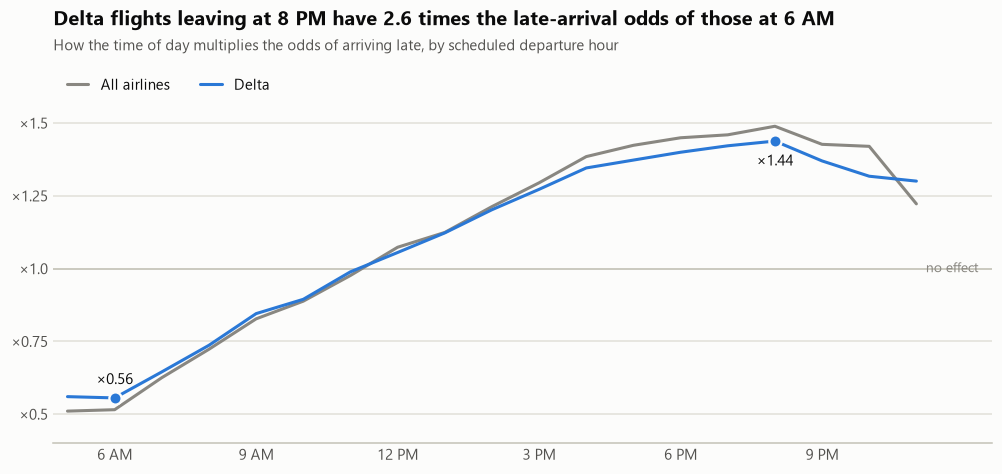

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(1, color=ps.AXIS, linewidth=1, zorder=1)
ax.plot(by_hour.index, by_hour["all_airlines"], color=ps.MUTED, label="All airlines", zorder=2)
ax.plot(by_hour.index, by_hour["delta"], color=ps.BLUE, label="Delta", zorder=3)
low, high = by_hour["delta"].idxmin(), by_hour["delta"].idxmax()
for hour, offset in [(low, 9), (high, -16)]:
    ax.plot(hour, by_hour.loc[hour, "delta"], marker="o", markersize=8, color=ps.BLUE,
            markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=4)
    ax.annotate(f"×{by_hour.loc[hour, 'delta']:.2f}", (hour, by_hour.loc[hour, "delta"]),
                xytext=(0, offset), textcoords="offset points", ha="center", color=ps.INK)
ax.text(by_hour.index[-1] + 0.2, 1, "no effect", va="center", ha="left", color=ps.MUTED, fontsize=9)
ax.set_xlim(by_hour.index[0] - 0.3, by_hour.index[-1] + 1.6)
ax.set_xticks([h for h in by_hour.index if h % 3 == 0], [hour_label(h) for h in by_hour.index if h % 3 == 0])
ax.set_ylim(0.4, 1.7)
ax.set_yticks([0.5, 0.75, 1.0, 1.25, 1.5], ["×0.5", "×0.75", "×1.0", "×1.25", "×1.5"])
ax.legend(loc="upper left", ncols=2, handlelength=1.4)
ps.title(ax, f"Delta flights leaving at {hour_label(high)} have {by_hour.loc[high, 'delta'] / by_hour.loc[low, 'delta']:.1f} times the late-arrival odds of those at {hour_label(low)}",
         "How the time of day multiplies the odds of arriving late, by scheduled departure hour")
ps.save(fig, "shap_time_of_day")
plt.show()

## 4. Turnaround time

`turnaround_minutes` is the scheduled time on the ground between the aircraft's previous flight and this one.

In [7]:
def diverging_bars(ax, values: pd.Series, labels: list[str]) -> None:
    """Bars to the right (red) raise the risk; bars to the left (blue) lower it. Values are log-odds pushes."""
    positions = list(range(len(values)))
    reach = max(abs(values.min()), abs(values.max())) * 1.35
    ax.set_xlim(-reach, reach)
    ax.set_ylim(len(values) - 0.5, -0.5)
    ax.set_yticks(positions, labels)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.axvline(0, color=ps.AXIS, linewidth=1, zorder=1)
    colors = [ps.RED if v > 0 else ps.BLUE for v in values]
    ps.barh_rounded(ax, positions, values.tolist(), colors, height=0.5)
    gap = reach * 0.02
    for pos, value in zip(positions, values):
        ax.text(value + (gap if value > 0 else -gap), pos, f"×{np.exp(value):.2f}", va="center",
                ha="left" if value > 0 else "right", color=ps.INK_2)
    ax.legend(handles=[Patch(color=ps.RED, label="Raises the risk"), Patch(color=ps.BLUE, label="Lowers the risk")],
              loc="upper center", bbox_to_anchor=(0.5, 0), ncols=2, handlelength=1.2, handleheight=0.9)

turnaround_labels = ["30–44 min", "45–59 min", "60–89 min", "90 min – 3 hours", "3–10 hours", "10+ hours (overnight)"]
turnaround = pd.cut(delta["turnaround_minutes"], [29, 44, 59, 89, 179, 599, 1440], labels=turnaround_labels)
by_turnaround = delta.groupby(turnaround, observed=True)[push("turnaround_minutes")].agg(["mean", "size"])
by_turnaround.assign(multiplier=np.exp(by_turnaround["mean"]).round(2))[["size", "multiplier"]]

,size,multiplier
turnaround_minutes,,
30–44 min,422,1.46
45–59 min,9081,1.00
60–89 min,21170,0.87
90 min – 3 hours,5321,0.78
3–10 hours,8301,0.85
10+ hours (overnight),5705,0.89


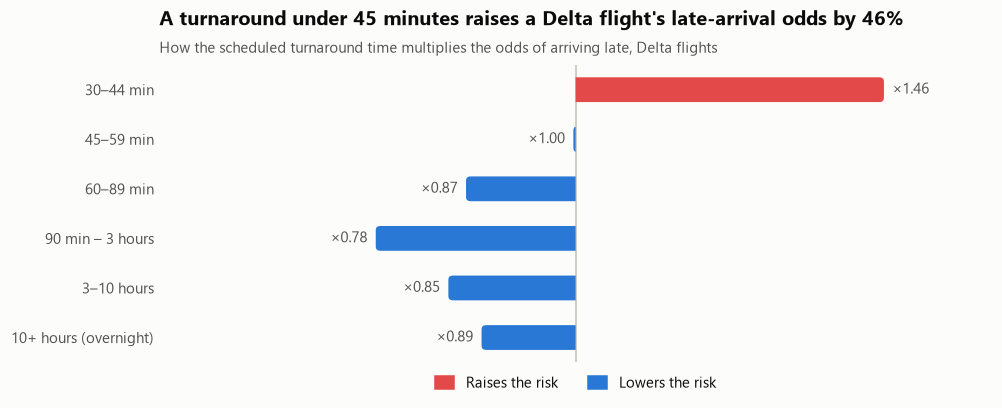

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
short = np.exp(by_turnaround["mean"].iloc[0])
ps.title(ax, f"A turnaround under 45 minutes raises a Delta flight's late-arrival odds by {100 * (short - 1):.0f}%",
         "How the scheduled turnaround time multiplies the odds of arriving late, Delta flights")
diverging_bars(ax, by_turnaround["mean"], list(by_turnaround.index))
ps.save(fig, "shap_turnaround")
plt.show()

## 5. Delta's busiest departure airports

The push from the `origin` feature, averaged over the Delta flights leaving each airport. Only airports with at least 1,000 flights in the sample are shown.

In [9]:
AIRPORT_NAMES = {
    "ATL": "Atlanta (ATL)", "MSP": "Minneapolis (MSP)", "DTW": "Detroit (DTW)", "SLC": "Salt Lake City (SLC)",
    "LAX": "Los Angeles (LAX)", "SEA": "Seattle (SEA)", "JFK": "New York JFK", "LGA": "New York LaGuardia (LGA)",
    "BOS": "Boston (BOS)", "MCO": "Orlando (MCO)",
}
by_origin = delta.groupby("origin", observed=True)[push("origin")].agg(["mean", "size"])
by_origin = by_origin[by_origin["size"] >= 1000].sort_values("mean")
by_origin.index = [AIRPORT_NAMES.get(code, code) for code in by_origin.index]
by_origin.assign(multiplier=np.exp(by_origin["mean"]).round(2))[["size", "multiplier"]]

,size,multiplier
Salt Lake City (SLC),2580,0.73
Los Angeles (LAX),1860,0.87
Seattle (SEA),1653,0.91
Atlanta (ATL),11641,0.94
Minneapolis (MSP),3376,1.02
New York JFK,1354,1.13
Detroit (DTW),2904,1.15
Boston (BOS),1308,1.23
New York LaGuardia (LGA),1286,1.40


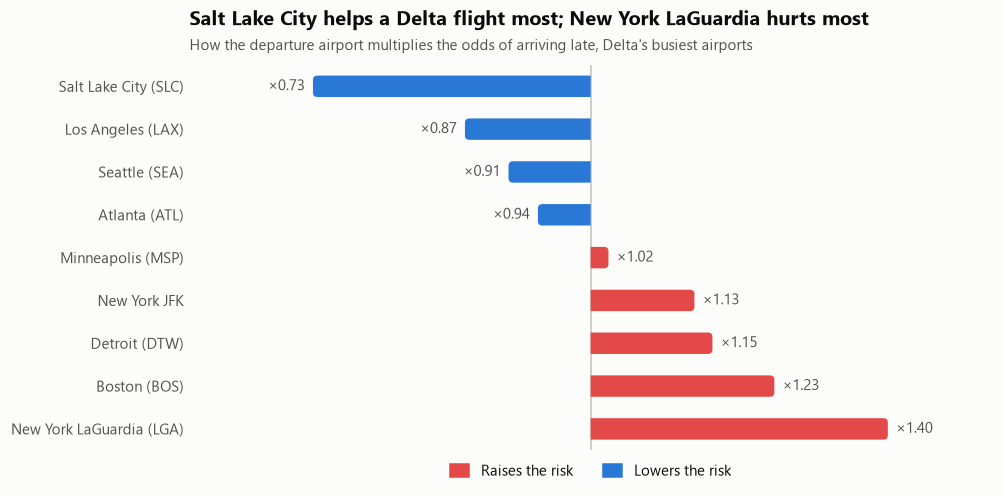

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.4))
best, worst = by_origin.index[0], by_origin.index[-1]
ps.title(ax, f"{best.split(' (')[0]} helps a Delta flight most; {worst.split(' (')[0]} hurts most",
         "How the departure airport multiplies the odds of arriving late, Delta's busiest airports")
diverging_bars(ax, by_origin["mean"], list(by_origin.index))
ps.save(fig, "shap_delta_airports")
plt.show()

## 6. Two single flights

SHAP can explain one prediction at a time. Below are two real Delta flights from the test months: one the model rated among the riskiest 1%, and one among the safest 1%. Each bar is one feature's push on that flight.

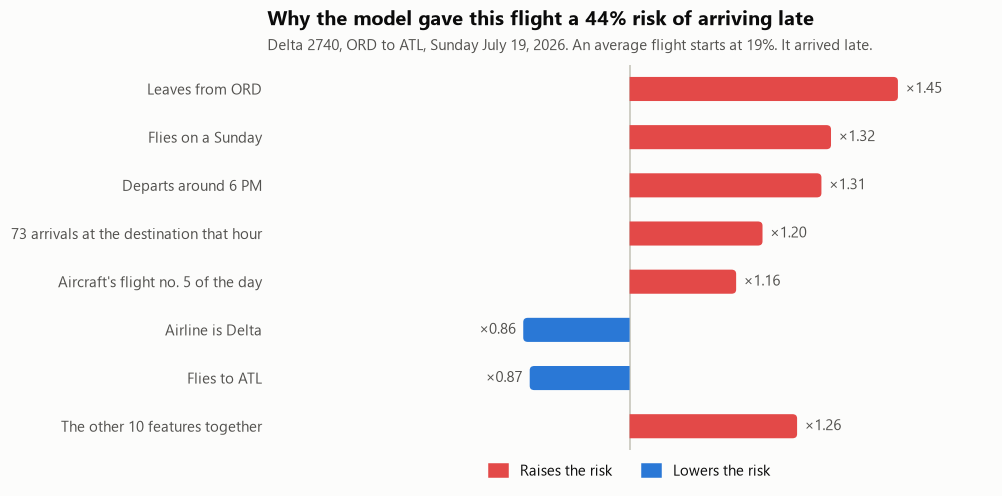

In [11]:
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def describe(feature: str, value) -> str:
    """A short, readable label for one feature value."""
    if feature == "departure_hour":
        return f"Departs around {hour_label(int(value))}"
    if feature == "arrival_hour":
        return f"Arrives around {hour_label(int(value))}"
    if feature == "day_of_week":
        return f"Flies on a {DAY_NAMES[int(value)]}"
    if feature == "origin":
        return f"Leaves from {value}"
    if feature == "destination":
        return f"Flies to {value}"
    if feature == "carrier":
        return "Airline is Delta"
    if feature == "previous_leg_origin":
        return f"Aircraft comes in from {value}"
    if feature == "turnaround_minutes":
        return f"Turnaround of {value / 60:.1f} hours" if value >= 180 else f"Turnaround of {value:.0f} minutes"
    if feature == "aircraft_leg_number":
        return f"Aircraft's flight no. {int(value)} of the day"
    if feature == "aircraft_legs_that_day":
        return f"Aircraft has {int(value)} flights that day"
    if feature == "aircraft_minutes_since_first_departure":
        return f"Aircraft in service for {value / 60:.1f} hours"
    if feature == "aircraft_family":
        return f"Aircraft is a {value}"
    if feature == "aircraft_age_years":
        return f"Aircraft is {value:.0f} years old"
    if feature == "origin_departures_that_hour":
        return f"{int(value)} departures at the origin that hour"
    if feature == "destination_arrivals_that_hour":
        return f"{int(value)} arrivals at the destination that hour"
    if feature == "distance_miles":
        return f"Distance of {int(value):,} miles"
    if feature == "scheduled_elapsed_minutes":
        return f"Scheduled flight time of {value / 60:.1f} hours"
    return f"{feature} = {value}"

def explain_flight(flight: pd.Series, name: str, shown: int = 7):
    pushes = pd.Series({f: flight[push(f)] for f in FEATURES})
    order = pushes.abs().sort_values(ascending=False).index
    main = pushes[order[:shown]]
    rest = pushes[order[shown:]].sum()
    values = pd.concat([main, pd.Series({"other": rest})])
    labels = [describe(f, flight[f]) for f in main.index] + [f"The other {len(FEATURES) - shown} features together"]

    fig, ax = plt.subplots(figsize=(9, 4.4))
    outcome = "It arrived late." if flight[TARGET] == 1 else "It arrived on time."
    ps.title(ax, f"Why the model gave this flight a {flight['risk']:.0%} risk of arriving late",
             f"Delta {int(flight['flight_number'])}, {flight['origin']} to {flight['destination']}, "
             f"{flight['flight_date']:%A %B %d, %Y}. An average flight starts at {starting_risk:.0%}. {outcome}")
    diverging_bars(ax, values, labels)
    ps.save(fig, name)
    plt.show()

ranked = delta.sort_values("risk").reset_index(drop=True)
risky_flight = ranked.iloc[int(len(ranked) * 0.99)]
safe_flight = ranked.iloc[int(len(ranked) * 0.01)]
explain_flight(risky_flight, "shap_one_risky_flight")

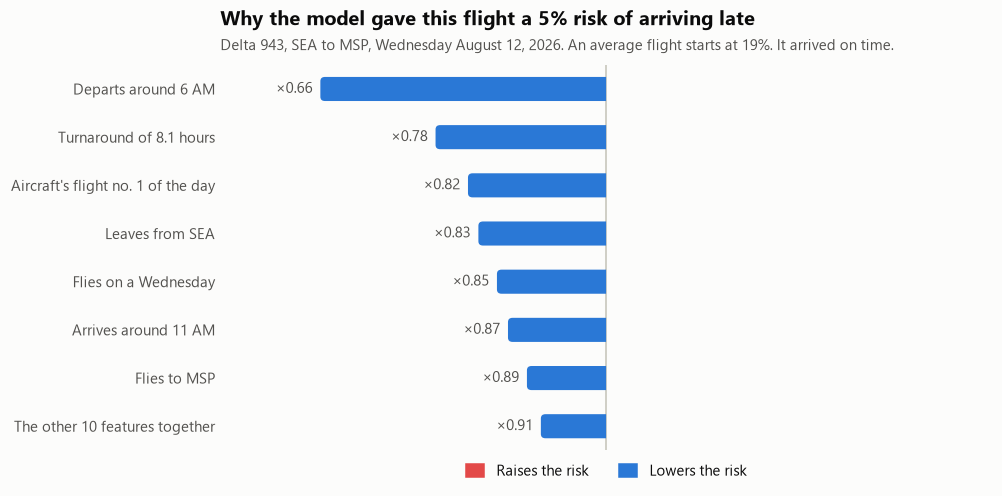

In [12]:
explain_flight(safe_flight, "shap_one_safe_flight")

## What we learned

1. **When and where a flight operates makes up 58% of the model's reasoning for Delta.** Time of day and weekday account for 31%, and route and airline for 27%. Aircraft rotation adds 21%, aircraft type and age 11%, and airport crowding 10%.
2. **Time of day is the biggest single driver.** A Delta flight leaving at 8 PM has 2.6 times the late-arrival odds of one leaving at 6 AM. Delta's curve follows the all-airline curve closely.
3. **Short turnarounds raise the risk.** A turnaround under 45 minutes raises the odds by 46%. Delta rarely schedules one (422 of the 50,000 flights). The lowest risk comes with 90 minutes to 3 hours on the ground.
4. **The departure airport matters.** Salt Lake City lowers a Delta flight's odds the most (×0.73) and New York LaGuardia raises them the most (×1.40). Atlanta, Delta's largest hub, is slightly better than average (×0.94).
5. **Being a Delta flight lowers the odds by about 10%** compared with an average airline, with everything else equal.
6. **Aircraft age barely registers** (under 2% of the total push), which confirms what notebook 02 found.
7. **Single predictions can be explained.** The model gave a Sunday 6 PM flight from Chicago O'Hare to Atlanta a 44% risk, and it arrived late. It gave a Wednesday 6 AM flight from Seattle to Minneapolis a 5% risk, and it arrived on time.

## Limits

- SHAP explains the model, not the real world. These are patterns the model found, not proven causes.
- The rotation and aircraft features describe the aircraft that actually flew, which can differ from the plan (see notebook 02).
- The explanations come from July and August 2026. Other seasons may look different.

## Next

The modeling work is complete. What remains is presenting it: the README with results, one Power BI page, and a resume bullet.

Charts from this notebook are saved in `reports/figures/`.